In [3]:
import geopandas as gpd

gdf = gpd.read_file("GLISM/glims_download_35490/glims_polygons.shp")

print(gdf.shape)
print(gdf.columns.tolist())
print(gdf.head())

d:\Kush\2nd Year\projects\glacier\implementation\venv\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: GLISM/glims_download_35490/glims_polygons.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


(617777, 36)
['line_type', 'anlys_id', 'glac_id', 'anlys_time', 'area', 'db_area', 'width', 'length', 'primeclass', 'min_elev', 'mean_elev', 'max_elev', 'src_date', 'rec_status', 'glac_name', 'wgms_id', 'local_id', 'glac_stat', 'gone_date', 'gone_dt_e', 'subm_id', 'release_dt', 'proc_desc', 'rc_id', 'geog_area', 'chief_affl', 'conn_lvl', 'surge_type', 'term_type', 'gtng_o1reg', 'gtng_o2reg', 'rgi_gl_typ', 'parent_id', 'submitters', 'analysts', 'geometry']
    line_type   anlys_id         glac_id           anlys_time    area  \
0  glac_bound   715234.0  G340953E63564N  1993-09-01T00:00:00  12.414   
1  glac_bound  1048878.0  G306386E70153N  2020-09-09T00:00:00   0.000   
2  glac_bound   409177.0  G222822E58665N  2015-07-16T00:00:00   0.777   
3  glac_bound   405377.0  G217968E60885N  2015-07-16T00:00:00   8.838   
4  glac_bound   405031.0  G217723E60374N  2015-07-16T00:00:00   0.201   

     db_area  width  length  primeclass  min_elev  ...  conn_lvl  surge_type  \
0  12.413600    0.0  

In [4]:
print(gdf.columns)

Index(['line_type', 'anlys_id', 'glac_id', 'anlys_time', 'area', 'db_area',
       'width', 'length', 'primeclass', 'min_elev', 'mean_elev', 'max_elev',
       'src_date', 'rec_status', 'glac_name', 'wgms_id', 'local_id',
       'glac_stat', 'gone_date', 'gone_dt_e', 'subm_id', 'release_dt',
       'proc_desc', 'rc_id', 'geog_area', 'chief_affl', 'conn_lvl',
       'surge_type', 'term_type', 'gtng_o1reg', 'gtng_o2reg', 'rgi_gl_typ',
       'parent_id', 'submitters', 'analysts', 'geometry'],
      dtype='object')


In [5]:
gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 617777 entries, 0 to 617776
Data columns (total 36 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   line_type   617777 non-null  object  
 1   anlys_id    617777 non-null  float64 
 2   glac_id     617777 non-null  object  
 3   anlys_time  617777 non-null  object  
 4   area        617777 non-null  float64 
 5   db_area     617777 non-null  float64 
 6   width       617777 non-null  float64 
 7   length      617777 non-null  float64 
 8   primeclass  617777 non-null  float64 
 9   min_elev    617777 non-null  float64 
 10  mean_elev   617777 non-null  float64 
 11  max_elev    617777 non-null  float64 
 12  src_date    617777 non-null  object  
 13  rec_status  617777 non-null  object  
 14  glac_name   617777 non-null  object  
 15  wgms_id     617777 non-null  object  
 16  local_id    617777 non-null  object  
 17  glac_stat   617777 non-null  object  
 18  gone_date   6177

# inspect the biggest glaciers.

In [6]:
largest = (
    gdf[['glac_id','glac_name','area','geog_area']]
    .sort_values('area', ascending=False)
)

print(largest.head(20))

               glac_id                     glac_name         area  \
208520  G008032E46504N      Grosser Aletschgletscher  105616000.0   
209469  G007800E45965N               Gornergletscher   65488500.0   
502016  G043100E43030N                       Bezengi   39410600.0   
208457  G008144E46504N           Fieschergletscher E   37372200.0   
502403  G043183E42984N                        Dyh-Cu   33609100.0   
208785  G008187E46569N             Unteraargletscher   33408000.0   
502647  G042766E43151N                       Lekziri   32770200.0   
502662  G043748E42782N                      Karaugom   28838500.0   
209256  G007964E46423N          Oberaletschgletscher   26560700.0   
209112  G008051E46567N  Unterer Grindelwaldgletscher   23242000.0   
503482  G042506E43356N                 Dzhikiugankez   23035000.0   
208499  G008156E46616N                Gauligletscher   22565900.0   
499328  G016345E67139N                    Salajiegna   21947100.0   
210258  G007880E45990N            

In [7]:
print(gdf['geog_area'].value_counts().head(20))

geog_area
Randolph Glacier Inventory; Umbrella RC for merging the RGI into GLIMS    144710
Asia                                                                      134766
Various (GlobGlacier)                                                      46918
China                                                                      44634
Himalaya (India, Nepal, Bhutan)                                            42368
European Alps                                                              28117
Northern Cordillera                                                        17567
Norway                                                                     17409
Chugach                                                                    16373
LIA outlines                                                               14800
Caucausus Region                                                           11067
swiss alps                                                                  9187
Juneau area       

In [8]:
gdf['centroid'] = gdf.geometry.centroid

gdf['lat'] = gdf.centroid.y
gdf['lon'] = gdf.centroid.x

C:\Users\KUSH\AppData\Local\Temp\ipykernel_29156\2418139977.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf['centroid'] = gdf.geometry.centroid
C:\Users\KUSH\AppData\Local\Temp\ipykernel_29156\2418139977.py:3: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf['lat'] = gdf.centroid.y
C:\Users\KUSH\AppData\Local\Temp\ipykernel_29156\2418139977.py:4: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf['lon'] = gdf.centroid.x


In [9]:
largest = (
    gdf[['glac_id','glac_name','area','lat','lon','geog_area']]
    .sort_values('area', ascending=False)
)

print(largest.head(20))

               glac_id                     glac_name         area        lat  \
208520  G008032E46504N      Grosser Aletschgletscher  105616000.0  46.490794   
209469  G007800E45965N               Gornergletscher   65488500.0  45.953102   
502016  G043100E43030N                       Bezengi   39410600.0  43.040705   
208457  G008144E46504N           Fieschergletscher E   37372200.0  46.512836   
502403  G043183E42984N                        Dyh-Cu   33609100.0  42.973520   
208785  G008187E46569N             Unteraargletscher   33408000.0  46.566178   
502647  G042766E43151N                       Lekziri   32770200.0  43.161006   
502662  G043748E42782N                      Karaugom   28838500.0  42.786209   
209256  G007964E46423N          Oberaletschgletscher   26560700.0  46.432823   
209112  G008051E46567N  Unterer Grindelwaldgletscher   23242000.0  46.570737   
503482  G042506E43356N                 Dzhikiugankez   23035000.0  43.358807   
208499  G008156E46616N                Ga

# choose glaciers from different climatic regimes.

In [10]:
gdf[gdf["geog_area"].str.contains("Greenland", case=False, na=False)][
    ["glac_id","glac_name","area","lat","lon"]
].sort_values("area", ascending=False).head(20)

,glac_id,glac_name,area,lat,lon
277777,G333751E69079N,reste,50701.0,69.079214,-26.249095
278290,G329763E69208N,CHRISTIAN IV GL.,5792.0,69.208008,-30.236598
278288,G329389E69966N,VESTFJORD GL.,5168.0,69.965652,-30.610888
278218,G330143E70706N,ROLIGE BR\x92,2428.0,70.706047,-29.856974
278272,G331717E69556N,None,2413.0,69.555710,-28.283205
278246,G330086E70975N,HARE GL.,2217.0,70.974908,-29.914406
278270,G328550E68813N,FREDERIKSBORG GL.,2066.0,68.813338,-31.450006
278226,G331862E69110N,BORGGRAVEN GL.,1861.0,69.109843,-28.137930
277782,G334078E69682N,None,1482.0,69.682065,-25.921529
277796,G332973E69448N,None,1482.0,69.448404,-27.027073


In [11]:
gdf[gdf["geog_area"].str.contains("Himal", case=False, na=False)][
    ["glac_id","glac_name","area","lat","lon"]
].sort_values("area", ascending=False).head(20)

,glac_id,glac_name,area,lat,lon
264165,G088173E27791N,None,94.51,27.787616,88.130686
265298,G086771E28015N,Ngojumba,82.61,28.039428,86.717515
264352,G088098E27633N,Yalung,81.91,27.645729,88.085575
265088,G085720E28299N,Langtang glacier,67.93,28.307292,85.702209
266021,G083319E28698N,None,57.15,28.702001,83.320084
265641,G084142E28500N,None,52.77,28.503467,84.124651
581562,G087062E27902N,Barun,52.41,27.903934,87.021920
581549,G087062E27902N,Barun,52.41,27.894262,87.056635
265070,G084459E28695N,None,46.25,28.715109,84.453844
265799,G083476E28736N,Dhaulagiri,46.05,28.732959,83.505818


In [12]:
gdf[gdf["geog_area"].str.contains("Cordillera|Alaska|Juneau|Chugach|Kenai",
                                  case=False, na=False)][
    ["glac_id","glac_name","area","lat","lon","geog_area"]
].sort_values("area", ascending=False).head(20)

,glac_id,glac_name,area,lat,lon,geog_area
341746,G225653E58752N,Taku Glacier,739.259,58.751882,-134.347394,Juneau area
340956,G225790E58568N,Taku Glacier,739.259,58.568297,-134.210347,Juneau area
340991,G225691E58672N,Taku Glacier,739.259,58.659109,-134.221198,Juneau area
340840,G225655E58741N,Taku Glacier,739.259,58.740975,-134.344827,Juneau area
340322,G225691E58672N,Taku Glacier,738.099,58.658533,-134.221003,Juneau area
339091,G225947E58607N,Taku Glacier,736.069,58.607529,-134.056995,Juneau area
338593,G225691E58672N,Taku Glacier,736.069,58.658455,-134.221153,Juneau area
338821,G225946E58613N,Taku Glacier,736.069,58.613213,-134.056476,Juneau area
337027,G225655E58741N,Taku Glacier,733.485,58.740975,-134.344827,Juneau area
337278,G225947E58607N,Taku Glacier,733.485,58.607447,-134.055197,Juneau area


### 1 glacier


In [13]:
aletsch = gdf[gdf["glac_name"]=="Grosser Aletschgletscher"]

print(aletsch[["glac_id","area"]])

poly = aletsch.iloc[0].geometry

print(poly.bounds)

               glac_id          area
208520  G008032E46504N  1.056160e+08
212771  G008032E46504N  7.835700e+01
214322  G008032E46504N  1.015100e-02
269549  G008032E46504N  8.233880e+01
326888  G008032E46504N  8.172740e+01
...                ...           ...
610872  G008032E46504N  0.000000e+00
610873  G008032E46504N  0.000000e+00
611082  G008032E46504N  0.000000e+00
611083  G008032E46504N  0.000000e+00
611084  G008032E46504N  0.000000e+00

[99 rows x 2 columns]
(7.932499, 46.372968, 8.091883, 46.563293)


### planetary comp


In [14]:
from pystac_client import Client
import planetary_computer

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

In [15]:
bbox = list(poly.bounds)

print(bbox)

[7.932499, 46.372968, 8.091883, 46.563293]


In [16]:
search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    datetime="2024-07-01/2024-09-30",
    query={"eo:cloud_cover": {"lt": 20}},
)

items = list(search.items())

print(len(items))

5


In [17]:
item = items[0]

print(item.id)

print(item.datetime)

print(item.assets.keys())

S2B_MSIL2A_20240823T101559_R065_T32TMS_20240823T145151
2024-08-23 10:15:59.024000+00:00
dict_keys(['AOT', 'B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B09', 'B11', 'B12', 'B8A', 'SCL', 'WVP', 'visual', 'safe-manifest', 'granule-metadata', 'inspire-metadata', 'product-metadata', 'datastrip-metadata', 'tilejson', 'rendered_preview'])


### visualize glacier 

In [18]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np

item = items[0]

for band in ["B04", "B03", "B02"]:
    print(item.assets[band].href)

https://sentinel2l2a01.blob.core.windows.net/sentinel2-l2/32/T/MS/2024/08/23/S2B_MSIL2A_20240823T101559_N0511_R065_T32TMS_20240823T145151.SAFE/GRANULE/L2A_T32TMS_A038987_20240823T102744/IMG_DATA/R10m/T32TMS_20240823T101559_B04_10m.tif?st=2026-06-18T07%3A29%3A11Z&se=2026-06-19T08%3A14%3A11Z&sp=rl&sv=2025-07-05&sr=c&skoid=9c8ff44a-6a2c-4dfb-b298-1c9212f64d9a&sktid=72f988bf-86f1-41af-91ab-2d7cd011db47&skt=2026-06-19T06%3A58%3A59Z&ske=2026-06-26T06%3A58%3A59Z&sks=b&skv=2025-07-05&sig=V9eOk9p5qK4NSbVRtEVu2Poy%2BgSSFpjxn1qXEZm4JeQ%3D
https://sentinel2l2a01.blob.core.windows.net/sentinel2-l2/32/T/MS/2024/08/23/S2B_MSIL2A_20240823T101559_N0511_R065_T32TMS_20240823T145151.SAFE/GRANULE/L2A_T32TMS_A038987_20240823T102744/IMG_DATA/R10m/T32TMS_20240823T101559_B03_10m.tif?st=2026-06-18T07%3A29%3A11Z&se=2026-06-19T08%3A14%3A11Z&sp=rl&sv=2025-07-05&sr=c&skoid=9c8ff44a-6a2c-4dfb-b298-1c9212f64d9a&sktid=72f988bf-86f1-41af-91ab-2d7cd011db47&skt=2026-06-19T06%3A58%3A59Z&ske=2026-06-26T06%3A58%3A59Z&sks=b&

In [28]:
from tqdm import tqdm
import rasterio
import time

bands = {}

band_names = ["B02", "B03", "B04"]

start_total = time.time()

for band in tqdm(band_names, desc="Downloading bands"):

    start_band = time.time()

    with rasterio.open(item.assets[band].href) as src:
        bands[band] = src.read(1)

    print(
        f"{band} done | shape={bands[band].shape} | "
        f"time={time.time()-start_band:.2f}s"
    )

print(f"Total time = {time.time()-start_total:.2f}s")

B02 done | shape=(10980, 10980) | time=161.72s


B03 done | shape=(10980, 10980) | time=139.51s


B04 done | shape=(10980, 10980) | time=119.21s
Total time = 420.52s


In [29]:
blue = bands["B02"]
green = bands["B03"]
red = bands["B04"]

print(red.shape)

(10980, 10980)


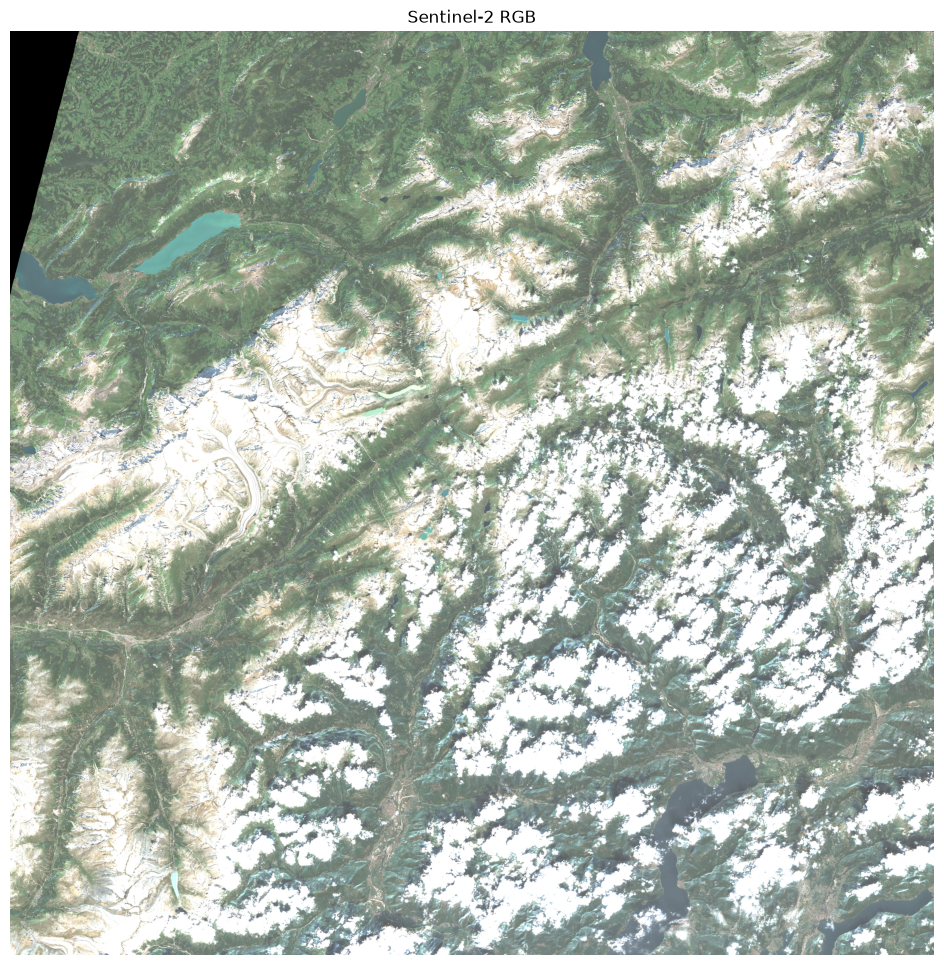

In [30]:
import numpy as np
import matplotlib.pyplot as plt

rgb = np.dstack([red, green, blue])

rgb = np.clip(rgb / 3000, 0, 1)

plt.figure(figsize=(12,12))
plt.imshow(rgb)
plt.title("Sentinel-2 RGB")
plt.axis("off")
plt.show()

In [31]:
with rasterio.open(item.assets["B04"].href) as src:

    print("CRS:", src.crs)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Bounds:", src.bounds)
    print("Resolution:", src.res)

CRS: EPSG:32632
Width: 10980
Height: 10980
Bounds: BoundingBox(left=399960.0, bottom=5090220.0, right=509760.0, top=5200020.0)
Resolution: (10.0, 10.0)


In [32]:
with rasterio.open(item.assets["B04"].href) as src:
    print(src.bounds)

BoundingBox(left=399960.0, bottom=5090220.0, right=509760.0, top=5200020.0)


In [33]:
print(poly.bounds)

(7.932499, 46.372968, 8.091883, 46.563293)


In [34]:
import geopandas as gpd

aletsch = gdf[gdf["glac_name"]=="Grosser Aletschgletscher"].copy()

with rasterio.open(item.assets["B04"].href) as src:
    target_crs = src.crs

aletsch = aletsch.to_crs(target_crs)

print(aletsch.geometry.iloc[0].bounds)

(418086.7681809763, 5135971.430922018, 430244.3818698325, 5157106.272141088)


In [35]:
from rasterio.windows import from_bounds

with rasterio.open(item.assets["B04"].href) as src:

    minx, miny, maxx, maxy = aletsch.geometry.iloc[0].bounds

    window = from_bounds(
        minx,
        miny,
        maxx,
        maxy,
        src.transform
    )

    red_crop = src.read(1, window=window)

print(red_crop.shape)

(2113, 1216)


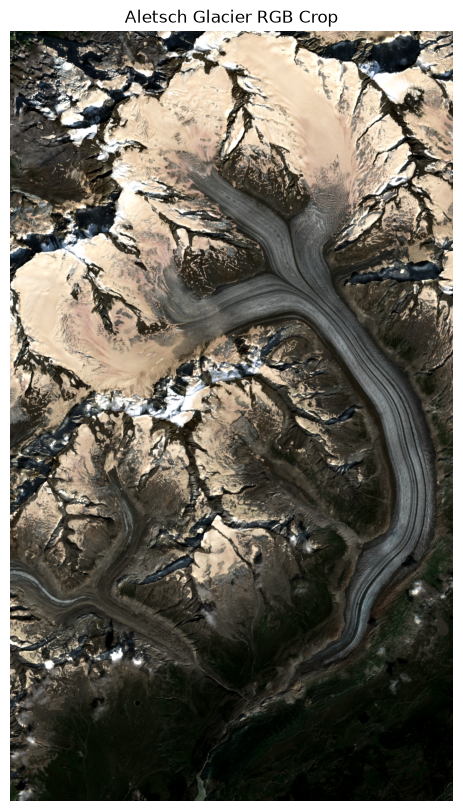

In [36]:
from rasterio.windows import from_bounds
import rasterio
import numpy as np
import matplotlib.pyplot as plt

minx, miny, maxx, maxy = aletsch.geometry.iloc[0].bounds

rgb_bands = {}

for band in ["B04", "B03", "B02"]:

    with rasterio.open(item.assets[band].href) as src:

        window = from_bounds(
            minx,
            miny,
            maxx,
            maxy,
            src.transform
        )

        rgb_bands[band] = src.read(1, window=window)

rgb = np.dstack([
    rgb_bands["B04"],
    rgb_bands["B03"],
    rgb_bands["B02"]
])

rgb = rgb.astype(np.float32)

# better stretch
p2, p98 = np.percentile(rgb, (2, 98))
rgb = np.clip((rgb - p2) / (p98 - p2), 0, 1)

plt.figure(figsize=(10,10))
plt.imshow(rgb)
plt.title("Aletsch Glacier RGB Crop")
plt.axis("off")
plt.show()

In [37]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np

nir = item.assets["B08"].href
swir1 = item.assets["B11"].href
swir2 = item.assets["B12"].href

In [38]:
bands_extra = {}

for band in ["B08","B11","B12"]:

    with rasterio.open(item.assets[band].href) as src:

        bands_extra[band] = src.read(
            1,
            window=window
        )

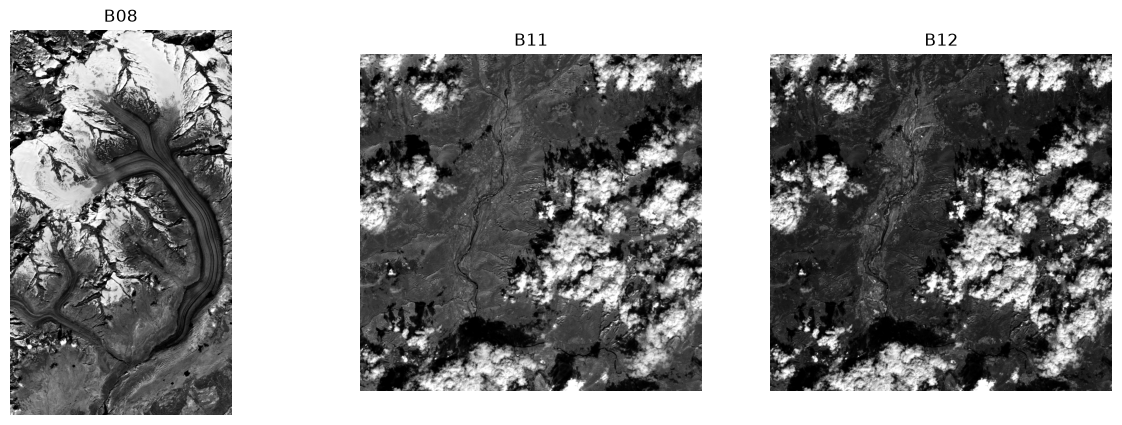

In [39]:
fig, ax = plt.subplots(1,3, figsize=(15,5))

for i, band in enumerate(["B08","B11","B12"]):

    img = bands_extra[band]

    p2, p98 = np.percentile(img, (2,98))

    img = np.clip(
        (img-p2)/(p98-p2),
        0,
        1
    )

    ax[i].imshow(img, cmap="gray")
    ax[i].set_title(band)
    ax[i].axis("off")

plt.show()

In [40]:
for band in ["B02","B03","B04","B08","B11","B12"]:
    with rasterio.open(item.assets[band].href) as src:
        print(
            band,
            src.res,
            src.width,
            src.height
        )

B02 (10.0, 10.0) 10980 10980
B03 (10.0, 10.0) 10980 10980
B04 (10.0, 10.0) 10980 10980
B08 (10.0, 10.0) 10980 10980
B11 (20.0, 20.0) 5490 5490
B12 (20.0, 20.0) 5490 5490


### Time Series

In [58]:
search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    datetime="2017-01-01/2025-12-31",
    query={"eo:cloud_cover":{"lt":20}}
)

items = sorted(
    list(search.items()),
    key=lambda x: x.datetime
)

print(len(items))

371


In [59]:
for item in items:
    print(item.datetime)

2017-02-16 10:21:01.026000+00:00
2017-03-11 10:30:11.026000+00:00
2017-03-28 10:20:21.026000+00:00
2017-04-10 10:30:21.026000+00:00
2017-05-27 10:20:31.026000+00:00
2017-06-19 10:30:21.026000+00:00
2017-06-26 10:20:21.026000+00:00
2017-07-04 10:30:19.027000+00:00
2017-07-06 10:20:21.026000+00:00
2017-07-19 10:30:21.026000+00:00
2017-08-05 10:20:31.026000+00:00
2017-08-15 10:20:21.026000+00:00
2017-08-23 10:30:19.027000+00:00
2017-08-25 10:20:21.026000+00:00
2017-09-22 10:30:09.027000+00:00
2017-10-07 10:30:21.026000+00:00
2017-10-12 10:30:09.027000+00:00
2017-10-14 10:20:21.026000+00:00
2017-10-17 10:30:21.026000+00:00
2017-10-19 10:20:19.028000+00:00
2017-10-24 10:21:11.026000+00:00
2017-11-03 10:22:01.026000+00:00
2017-11-16 10:33:11.026000+00:00
2017-11-18 10:23:09.027000+00:00
2017-12-06 10:34:21.026000+00:00
2017-12-13 10:24:31.026000+00:00
2017-12-21 10:34:29.027000+00:00
2017-12-31 10:34:29.027000+00:00
2018-03-28 10:20:19.027000+00:00
2018-04-02 10:20:21.026000+00:00
2018-04-07

In [60]:
from collections import defaultdict

best_per_year = {}

for scene in items:

    year = scene.datetime.year

    month = scene.datetime.month

    if month not in [7, 8, 9]:
        continue

    cloud = scene.properties["eo:cloud_cover"]

    if (
        year not in best_per_year
        or cloud < best_per_year[year].properties["eo:cloud_cover"]
    ):
        best_per_year[year] = scene

for year in sorted(best_per_year):
    print(
        year,
        best_per_year[year].datetime,
        best_per_year[year].properties["eo:cloud_cover"]
    )

2017 2017-08-23 10:30:19.027000+00:00 4.098929
2018 2018-09-27 10:30:19.024000+00:00 0.376291
2019 2019-09-12 10:30:19.024000+00:00 1.051067
2020 2020-08-07 10:25:59.024000+00:00 1.1326
2021 2021-08-14 10:20:31.024000+00:00 2.24417
2022 2022-07-18 10:25:59.024000+00:00 0.992905
2023 2023-09-26 10:28:01.024000+00:00 0.016495
2024 2024-07-04 10:15:59.025000+00:00 14.379981
2025 2025-08-08 10:27:01.024000+00:00 0.156713


In [61]:
import planetary_computer
import rasterio
import numpy as np
from rasterio.windows import from_bounds

def get_rgb_crop(scene, glacier_geom):

    # Re-sign URLs every time
    scene = planetary_computer.sign(scene)

    minx, miny, maxx, maxy = glacier_geom.bounds

    bands = {}

    for band in ["B04", "B03", "B02"]:

        with rasterio.open(scene.assets[band].href) as src:

            window = from_bounds(
                minx,
                miny,
                maxx,
                maxy,
                src.transform
            )

            bands[band] = src.read(1, window=window)

    rgb = np.dstack([
        bands["B04"],
        bands["B03"],
        bands["B02"]
    ]).astype(np.float32)

    p2, p98 = np.percentile(rgb, (2, 98))

    rgb = np.clip(
        (rgb - p2) / (p98 - p2),
        0,
        1
    )

    return rgb 

In [62]:
img = get_rgb_crop(
    best_per_year[2017],
    glacier_geom
)

print(img.shape)

(2113, 1216, 3)


In [63]:
import planetary_computer

scene = best_per_year[2017]

print(type(scene))
print(scene.assets["B04"].href[:150])

<class 'pystac.item.Item'>
https://sentinel2l2a01.blob.core.windows.net/sentinel2-l2/32/T/MS/2017/08/23/S2B_MSIL2A_20170823T103019_N0212_R108_T32TMS_20210207T123140.SAFE/GRANULE


In [64]:
signed_scene = planetary_computer.sign(scene)

print(signed_scene.assets["B04"].href[:150])

https://sentinel2l2a01.blob.core.windows.net/sentinel2-l2/32/T/MS/2017/08/23/S2B_MSIL2A_20170823T103019_N0212_R108_T32TMS_20210207T123140.SAFE/GRANULE


In [65]:
url = signed_scene.assets["B04"].href

print(url)

https://sentinel2l2a01.blob.core.windows.net/sentinel2-l2/32/T/MS/2017/08/23/S2B_MSIL2A_20170823T103019_N0212_R108_T32TMS_20210207T123140.SAFE/GRANULE/L2A_T32TMS_A002422_20170823T103018/IMG_DATA/R10m/T32TMS_20170823T103019_B04_10m.tif?st=2026-06-18T09%3A04%3A31Z&se=2026-06-19T09%3A49%3A31Z&sp=rl&sv=2025-07-05&sr=c&skoid=9c8ff44a-6a2c-4dfb-b298-1c9212f64d9a&sktid=72f988bf-86f1-41af-91ab-2d7cd011db47&skt=2026-06-19T08%3A36%3A39Z&ske=2026-06-26T08%3A36%3A39Z&sks=b&skv=2025-07-05&sig=IKvJ51cpGpGGfqpvrKhKyDpGcaTJsLgu6MPMAcKjPvY%3D


In [67]:
from tqdm import tqdm

yearly_images = {}

for year in tqdm(sorted(best_per_year.keys())):

    yearly_images[year] = get_rgb_crop(
        best_per_year[year],
        glacier_geom
    )

100%|██████████| 9/9 [03:48<00:00, 25.40s/it]


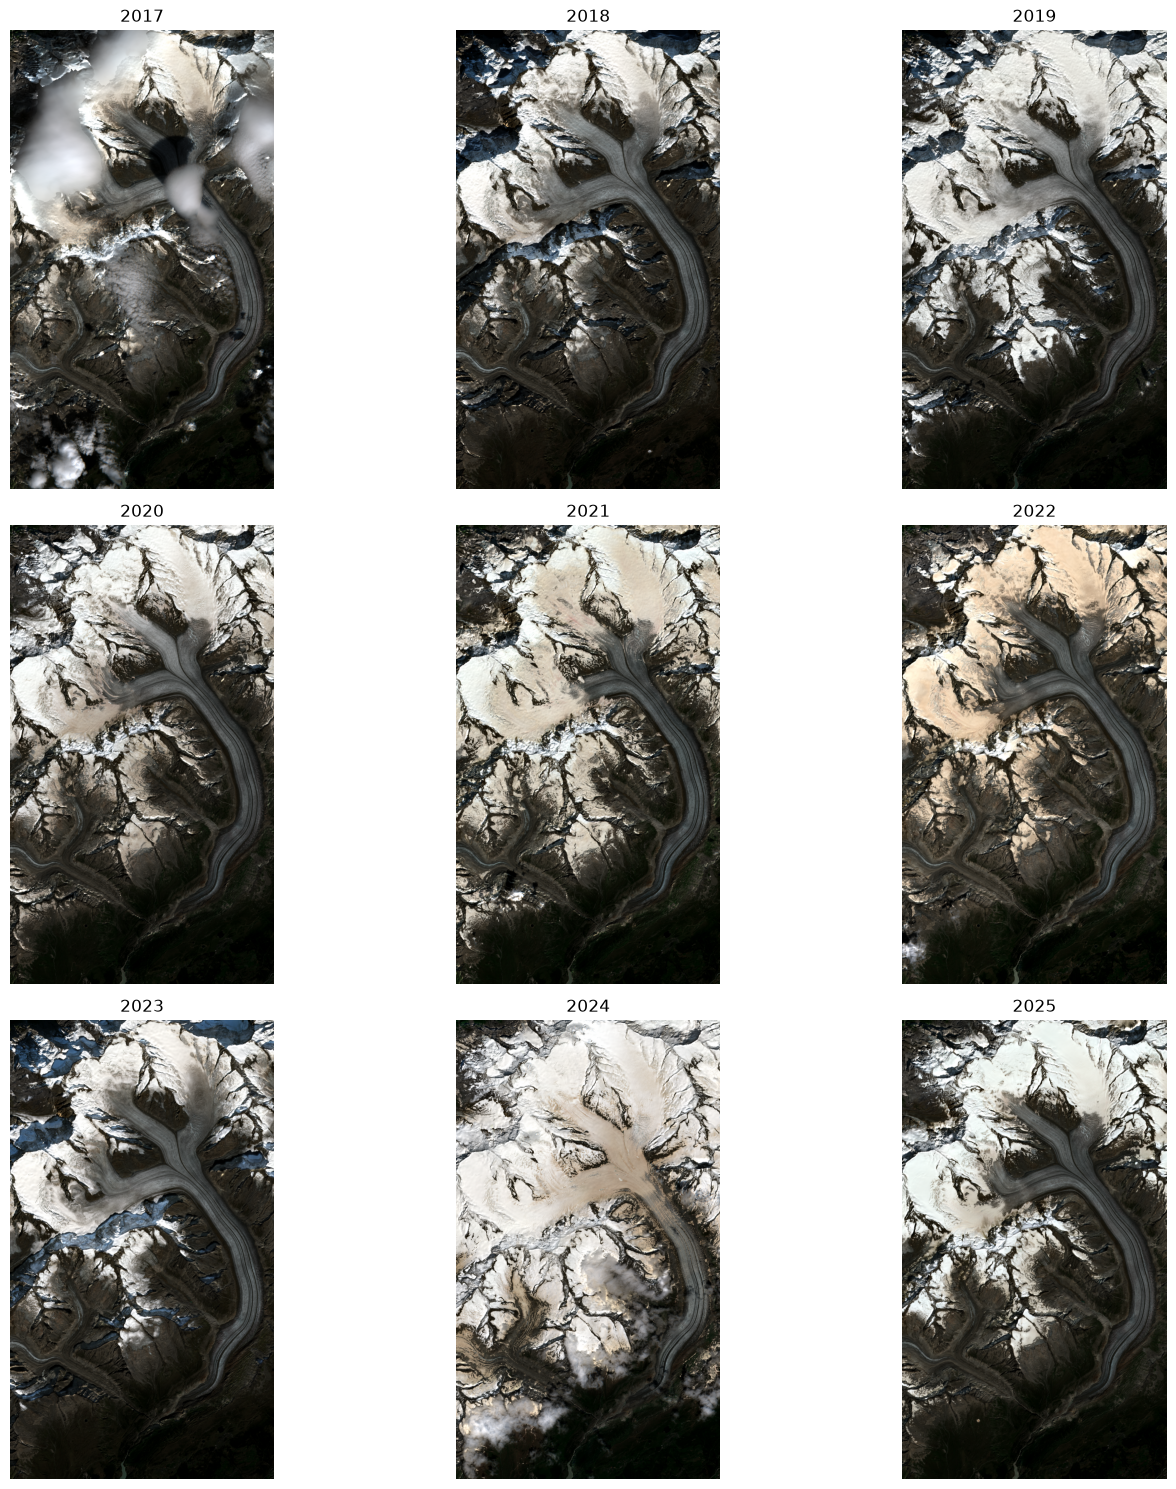

In [68]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    3,
    3,
    figsize=(15,15)
)

axes = axes.flatten()

for ax, year in zip(axes, sorted(yearly_images.keys())):

    ax.imshow(yearly_images[year])
    ax.set_title(str(year))
    ax.axis("off")

plt.tight_layout()
plt.show()